# Blood pressure — overall contrasts and treatment changes

Based on `analyse fits-bp(1).ipynb`. The original analysis loads **three separate models** (`baseline`, `vehicle`, `empa`) with coefficients for genotype, age, sex, genotype × age, and genotype × sex.

- **Baseline 1**, **Vehicle**, and **Empa**: overall genotype, age, and sex contrasts within each fitted model.
- **Vehicle** and **Empa**: modeled BP changes themselves, averaged over age and sex for `fa/+` and `fa/fa`, plus the equally weighted overall change.

**Important:** In the original notebook, Vehicle and Empa posterior predictions represent *BP changes*, not absolute BP. Accordingly, the second plot displays each treatment's modeled change relative to zero; it does **not** subtract Vehicle from Empa or subtract Baseline 1. The three models are fitted separately.


## Imports and fitted models

In [30]:
import arviz as az
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kidney.paths import RESULTS_DIR, PLOT_DIR
from kidney.plotting import forestplot_oz
from kidney.sign_probs import get_sign_probs, get_signif
from kidney.contrasts import get_overall_effects

az.rcParams["data.load"] = "eager"
plt.rcParams["pdf.fonttype"] = 42

idata = {
    "Baseline 2": az.from_netcdf(RESULTS_DIR / "idata_bp_baseline.nc"),
    "Vehicle": az.from_netcdf(RESULTS_DIR / "idata_bp_vehicle.nc"),
    "Empa": az.from_netcdf(RESULTS_DIR / "idata_bp_empa.nc"),
}


## Group predictors

The original notebook uses `Intercept` plus the five coefficients `gtyp`, `age`, `sex`, `gtyp:age`, and `gtyp:sex`. We preserve that structure, but use comma-separated group keys to work with `kidney.contrasts.get_overall_effects`.

`get_t_groups()` from `kidney.contrasts` intentionally excludes the intercept, which is correct for *contrasts* but **not** for the actual BP-change plot. Therefore this notebook adds the intercept to each group prediction.


In [31]:
GTYPS = ("fa/+", "fa/fa")
SEXES = ("female", "male")
AGES = ("adult", "young")

def posterior_term(idata, name):
    da = idata.posterior[name]
    extra_dims = [dim for dim in da.dims if dim not in ("chain", "draw")]
    if any(da.sizes[dim] != 1 for dim in extra_dims):
        raise ValueError(f"{name} has multiple coefficients; inspect reference levels: {da.dims}")
    return da.isel({dim: 0 for dim in extra_dims}, drop=True)

def bp_group_means(idata):
    """Population-level mean BP or BP change for all eight groups."""
    intercept = posterior_term(idata, "Intercept")
    g = posterior_term(idata, "gtyp")
    a = posterior_term(idata, "age")
    s = posterior_term(idata, "sex")
    ga = posterior_term(idata, "gtyp:age")
    gs = posterior_term(idata, "gtyp:sex")

    return {
        "fa/+,female,adult": intercept,
        "fa/+,female,young": intercept + a,
        "fa/+,male,adult": intercept + s,
        "fa/+,male,young": intercept + s + a,
        "fa/fa,female,adult": intercept + g,
        "fa/fa,female,young": intercept + g + a + ga,
        "fa/fa,male,adult": intercept + g + s + gs,
        "fa/fa,male,young": intercept + g + s + gs + a + ga,
    }

groups = {stage: bp_group_means(fit) for stage, fit in idata.items()}


## 1. Overall genotype, age, and sex contrasts by stage

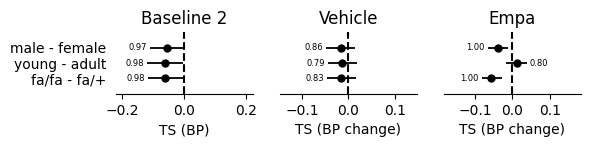

In [37]:
overall_effects = {
    stage: get_overall_effects(stage_groups)
    for stage, stage_groups in groups.items()
}

fig, axes = plt.subplots(1, 3, figsize=(6, 0.8), sharey=True)
for i, (ax, stage) in enumerate(zip(axes, ("Baseline 2", "Vehicle", "Empa"))):
    forestplot_oz(ax, overall_effects[stage], sign_probs=True)
    ax.set_title(stage)
    ax.set_xlabel("TS (BP)" if stage == "Baseline 2" else "TS (BP change)")
    ax.spines[["top", "right", "left"]].set_visible(False)
    if i:
        ax.tick_params(axis="y", left=False, labelleft=False)

fig.savefig(PLOT_DIR / "ts_bp_overall_effects.pdf", bbox_inches="tight")

## 2. Modeled BP change itself: Vehicle and Empa

Each genotype-specific effect is averaged equally over female/male and adult/young. The overall effect is the equally weighted average across all eight groups. Because these are absolute fitted changes, the intercept is retained.


In [33]:
def get_bp_change_by_genotype(t_groups):
    def average(gtyp):
        return sum(
            t_groups[f"{gtyp},{sex},{age}"]
            for sex in SEXES for age in AGES
        ) / (len(SEXES) * len(AGES))

    fa_plus = average("fa/+")
    fa_fa = average("fa/fa")
    return {
        "fa/fa": fa_fa,
        "fa/+": fa_plus,
        # "Overall": (fa_plus + fa_fa) / 2,
    }

change_effects = {
    stage: get_bp_change_by_genotype(groups[stage])
    for stage in ("Vehicle", "Empa")
}

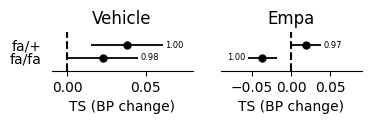

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(4, 0.5), sharey=True)
for i, (ax, stage) in enumerate(zip(axes, ("Vehicle", "Empa"))):
    forestplot_oz(ax, change_effects[stage], sign_probs=True)
    ax.set_title(stage)
    ax.set_xlabel("TS (BP change)")
    ax.spines[["top", "right", "left"]].set_visible(False)
    if i:
        ax.tick_params(axis="y", left=False, labelleft=False)

axes[0].set_xlim(-0.01, 0.08)
axes[1].set_xlim(-0.09, 0.09)
fig.savefig(PLOT_DIR / "ts_bp_changes_by_genotype.pdf", bbox_inches="tight")

## 3. Posterior sign probabilities and significance

In [35]:
def sign_table(effect_sets):
    return pd.concat(
        {
            stage: pd.DataFrame({
                "sign_probability": (probs := get_sign_probs(effects)),
                "significance": {k: get_signif(v) for k, v in probs.items()},
            })
            for stage, effects in effect_sets.items()
        },
        names=["stage", "contrast"],
    )

sp_overall = sign_table(overall_effects)
sp_changes = sign_table(change_effects)

display(sp_overall)
display(sp_changes)


sign_probability significance
stage      contrast                                    
Baseline 2 fa/fa - fa/+            0.01900            *
           young - adult           0.01950            *
           male - female           0.02700             
Vehicle    fa/fa - fa/+            0.17425             
           young - adult           0.20675             
           male - female           0.14375             
Empa       fa/fa - fa/+            0.00000            *
           young - adult           0.79600             
           male - female           0.00150            *

sign_probability significance
stage   contrast                               
Vehicle fa/fa               0.9785            *
        fa/+                0.9990            *
Empa    fa/fa               0.0005            *
        fa/+                0.9750